# N134 — archived MPC with/without task-retention guard

Stage: **stopped** · updated 2026-11-03 00:08:04.

Two independent runs, SAME N132 parent, SAME67,724 BDD keyframes and image seeds. Archived N10988-feature H2 controller, coefficients/prior/monitor bank unchanged; no refit. Rates0/1⁄16/1⁄4 nominal,5% exploration, online health feedback.

Both8,192-image prefixes run first, then BOTH continue to67,724 without an outcome gate. Validation:7,844 separate queries,12 refitted fifty-label probes; one training seed/order.

| Arm | Progress | Updates | Probe at | Linear accuracy % | Worst cell % | CE | Guard rejects | Explored updates |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| legacy_h2 | 67,724 | 12,664 | 67,724 | **60.856** | 52.225 | 0.828286 | 0 | 3,399 |
| legacy_h2_guarded | 43,008 | 1,195 | 40,960 | **60.306** | 49.862 | 0.757227 | 17,388 | 132 |

Probe arrival and training progress differ: independent readouts every4,096 arrivals. Accuracy is the primary display; all four conditions and CE remain visible.

The added guard permits cell CE<=max(parent+.02,current) and<=current+.002. Unguarded shadow measurements never affect control. Rejected guarded steps restore full learner/Adam/RNG state and provide no predictor training labels.

## Plant model and transfer evidence

The original ridge forecasts RankMe, reconstruction and variance under actions; H2 holds unmodelled future image context fixed. Its archived fit came from a different training history/plant: input support and forecast error must be checked on this transferred run.

**legacy_h2**: 12664 measured attempted actions; mean out-of-range input fraction 19.7%. Shadow guard would reject 4321 attempts.

| Output | Online RMSE | Frozen shadow RMSE | Persistence RMSE | MSE gain vs persistence |
|---|---:|---:|---:|---:|
| RankMe | 0.00566956 | 0.0173342 | 0.00785297 | +47.9% |
| Reconstruction | 0.000208112 | 0.00205048 | 0.000202108 | -6.0% |
| Variance | 1.30842e-05 | 3.99394e-05 | 1.76423e-05 | +45.0% |

**legacy_h2_guarded**: 18583 measured attempted actions; mean out-of-range input fraction 18.5%. Shadow guard would reject 17388 attempts.

| Output | Online RMSE | Frozen shadow RMSE | Persistence RMSE | MSE gain vs persistence |
|---|---:|---:|---:|---:|
| RankMe | 0.00170766 | 0.00363949 | 0.00168286 | -3.0% |
| Reconstruction | 0.000169747 | 0.00107673 | 0.000109768 | -139.1% |
| Variance | 6.15471e-06 | 1.92626e-05 | 6.36986e-06 | +6.6% |

Committed/rejected breakdowns are saved in plant-diagnostics.json. Forecast quality on tested actions does not by itself establish beneficial-action selection. Independent linear-probe accuracy is not a predicted plant state.

Cost accounting separates context/planning/training/health/adaptation, mandatory guard-canary work, optional unguarded shadow-canary work, independent evaluation and checkpoints. No equal-compute or population-safety claim is assumed.

Error: Explicit stop request; intact checkpoints retained


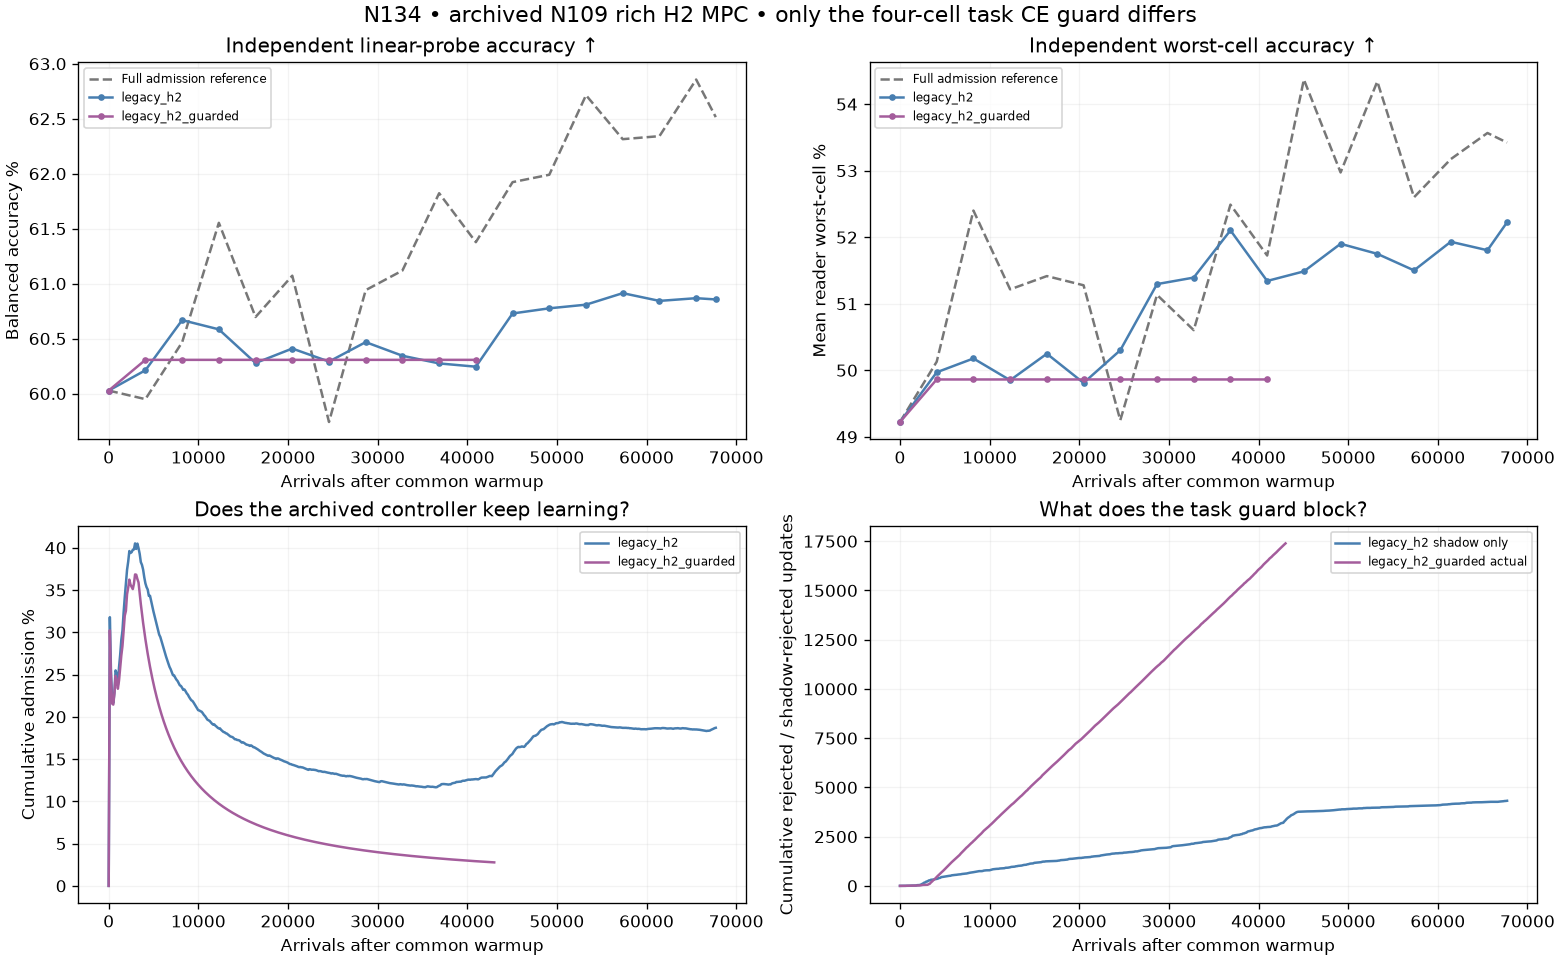

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\legacy-mpc-guard\\20261102-n134\\live.png'))


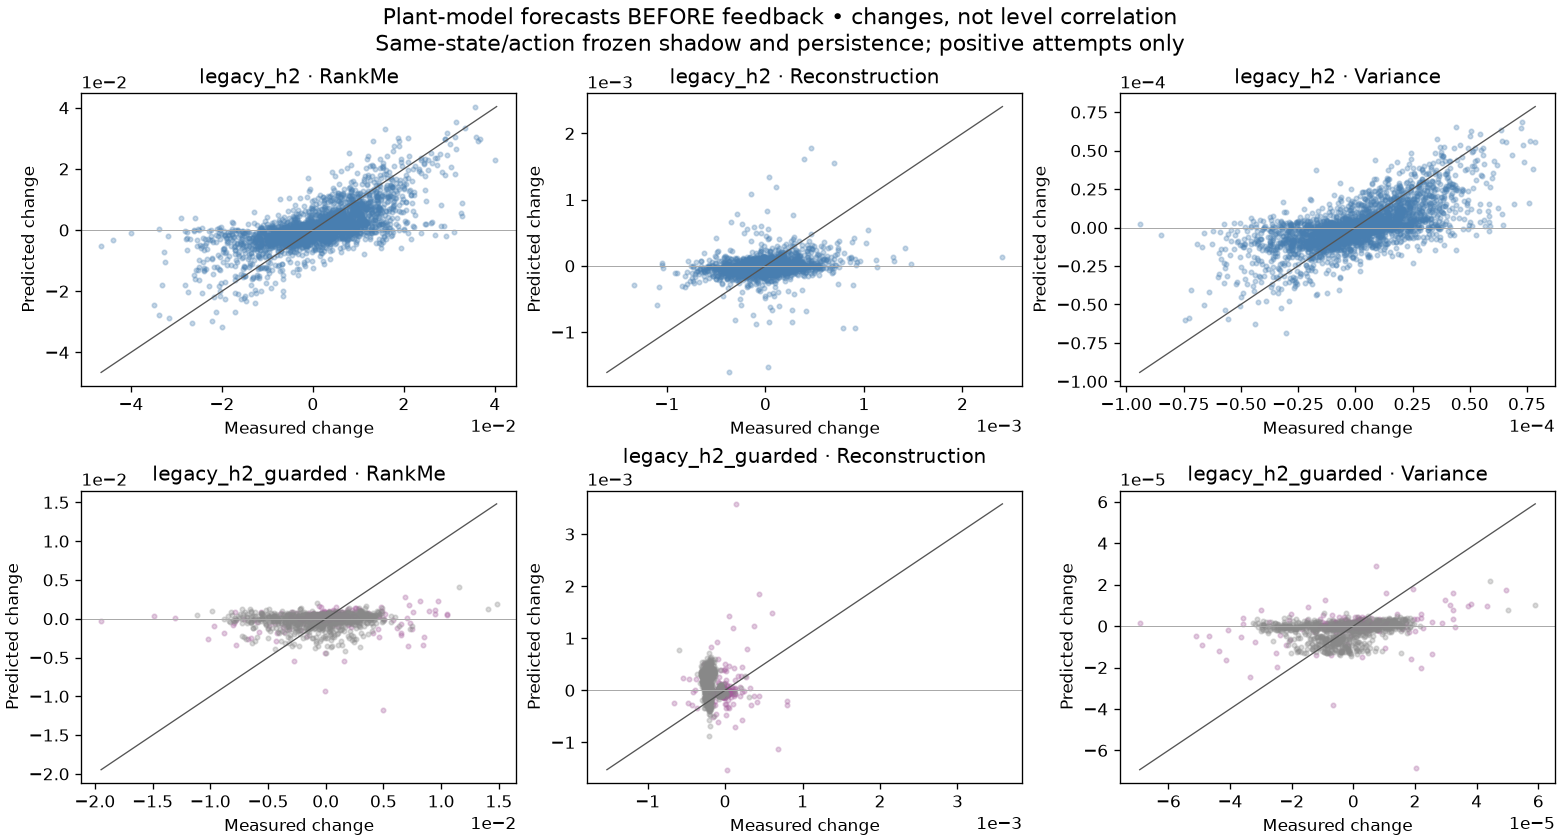

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\legacy-mpc-guard\\20261102-n134\\plant-model.png'))


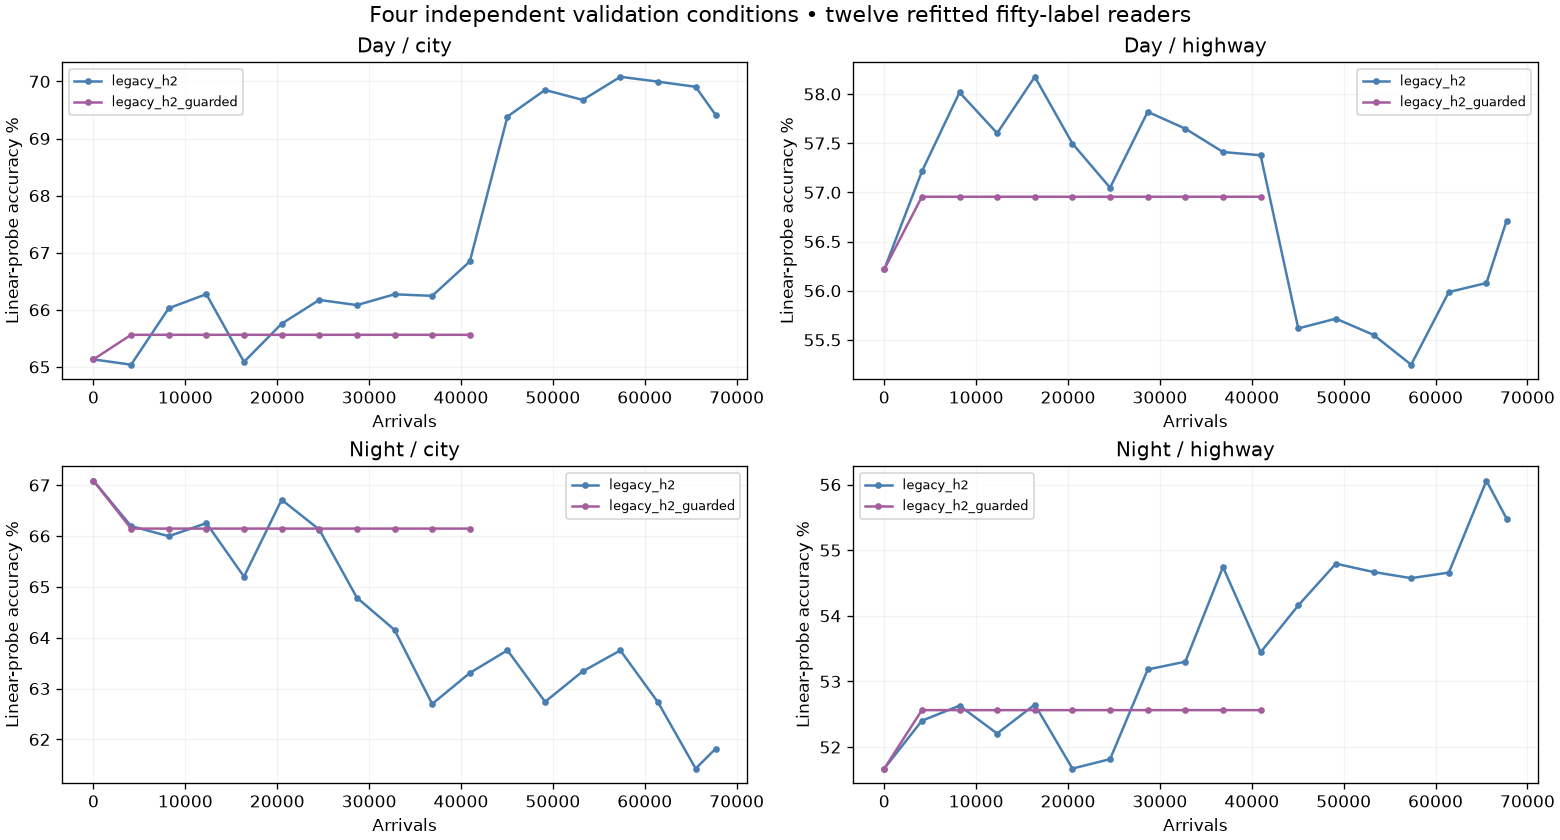

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\legacy-mpc-guard\\20261102-n134\\cell-accuracy.png'))
